# Optimizer 2: Stochastic Gradient Descent (SGD)

تطبيق **SGD** على مشكلة Regression (California Housing) — Linear Regression مكتوب من الصفر بـ NumPy.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 1) الداتا سيت — California Housing

داتا سيت **Regression** مشهورة (مضمّنة بمكتبة `scikit-learn`)، فيها **20,640** عيّنة و **8** features:

| Feature | الوصف |
|---|---|
| `MedInc` | متوسط دخل سكان المنطقة |
| `HouseAge` | متوسط عمر البيوت |
| `AveRooms` | متوسط عدد الغرف |
| `AveBedrms` | متوسط عدد غرف النوم |
| `Population` | عدد السكان |
| `AveOccup` | متوسط عدد الساكنين بالبيت |
| `Latitude` / `Longitude` | الموقع الجغرافي |

**الـ Target:** `MedHouseVal` = متوسط سعر البيت (بوحدة 100,000$).

> على **Kaggle** لازم تكون الـ Internet مفعّلة (Settings → Internet → On) حتى تنزل الداتا. على **Colab** بتشتغل مباشرة.

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame
print("Shape:", df.shape)
df.head()

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


Missing values: 0


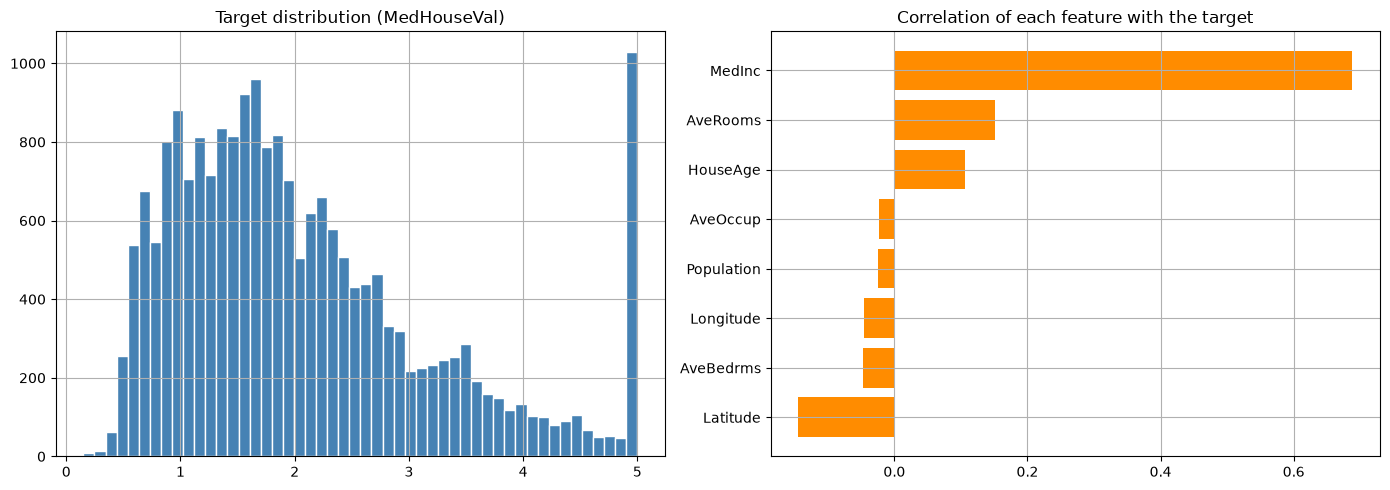

In [3]:
display(df.describe().T.round(2))
print("Missing values:", df.isna().sum().sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df["MedHouseVal"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Target distribution (MedHouseVal)")
corr = df.corr()["MedHouseVal"].drop("MedHouseVal").sort_values()
axes[1].barh(corr.index, corr.values, color="darkorange")
axes[1].set_title("Correlation of each feature with the target")
plt.tight_layout(); plt.show()

## 2) تجهيز الداتا

- تقسيم **80% train / 20% test**.
- **Clipping للـ outliers**: بعض الـ features (متل `AveOccup` و `Population`) فيها قيم شاذة ضخمة (أكتر من 100 standard deviation!). هالقيم بتخلّي الـ gradient لعيّنة وحدة ضخم وبتعمل **divergence** خصوصاً بالـ SGD. لهيك منقصّ كل feature بين الـ percentile 1 و 99 تبع الـ train.
- **Standardization** للـ features (mean=0, std=1) — مهمة جداً لكل الـ optimizers المبنية على الـ gradient، لأنها بتخلّي سطح الـ loss متناسق وبتسمح بـ learning rate أكبر.
- الـ scaler بيتعلّم من الـ train بس (لتجنّب data leakage).

In [4]:
X = df.drop(columns="MedHouseVal").values
y = df["MedHouseVal"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Clip outliers to the 1st-99th percentile of the TRAIN set (winsorization)
low, high = np.percentile(X_train, [1, 99], axis=0)
print("Max |z| before clipping:", np.abs((X_train - X_train.mean(0)) / X_train.std(0)).max().round(1))
X_train = np.clip(X_train, low, high)
X_test = np.clip(X_test, low, high)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

n_samples, n_features = X_train.shape
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Max |z| before clipping: 107.1
Train: (16512, 8) | Test: (4128, 8)


## 3) الموديل: Linear Regression من الصفر (NumPy)

$$\hat{y} = Xw + b$$

**Loss (MSE):**
$$L(w,b) = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2$$

**Gradients:**
$$\frac{\partial L}{\partial w} = \frac{2}{n}X^T(\hat{y}-y), \qquad \frac{\partial L}{\partial b} = \frac{2}{n}\sum(\hat{y}-y)$$

بنكتب الموديل يدوياً بدل ما نستخدم مكتبة جاهزة، حتى نشوف شو بيعمل الـ optimizer بالضبط بكل خطوة.

In [5]:
def predict(X, w, b):
    return X @ w + b

def mse(X, y, w, b):
    return np.mean((predict(X, w, b) - y) ** 2)

def gradients(X, y, w, b):
    n = X.shape[0]
    err = predict(X, w, b) - y
    dw = (2 / n) * (X.T @ err)
    db = (2 / n) * np.sum(err)
    return dw, db

def evaluate(name, X, y, w, b):
    y_pred = predict(X, w, b)
    res = {
        "Model": name,
        "MSE": mean_squared_error(y, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y, y_pred)),
        "MAE": mean_absolute_error(y, y_pred),
        "R2": r2_score(y, y_pred),
    }
    return res

## 4) Baseline: الحل المغلق (Normal Equation)

`sklearn.LinearRegression` بيحسب الحل الأمثل مباشرة بدون أي optimizer. هاد هو **أقل MSE ممكن** للموديل الخطي، فبنقارن فيه حتى نعرف قديش الـ optimizer تبعنا قرّب من الحل الأمثل.

In [6]:
ref = LinearRegression().fit(X_train, y_train)
best_train_mse = mean_squared_error(y_train, ref.predict(X_train))
print(f"Optimal train MSE (closed form): {best_train_mse:.5f}")
print(f"Optimal test  MSE (closed form): {mean_squared_error(y_test, ref.predict(X_test)):.5f}")

Optimal train MSE (closed form): 0.42834
Optimal test  MSE (closed form): 0.44923


## 5) الـ Optimizer: SGD

**SGD** بيحسب الـ gradient على **عيّنة وحدة بس** بكل خطوة، فبيعمل `n` updates بكل epoch:

$$w \leftarrow w - \eta \, \nabla_w L(x_i, y_i)$$

- ✅ updates كتيرة وسريعة، بيقرّب من الحل بعدد epochs قليل.
- ✅ الضجيج (noise) ممكن يساعد يطلع من local minima (بالموديلات غير الخطية).
- ❌ الـ loss بيتذبذب كتير وما بيستقر تماماً عند الحل إلا إذا نزّلنا الـ learning rate (learning-rate decay).

In [7]:
def train(lr=0.001, epochs=20, decay=0.0):
    w = np.zeros(n_features)
    b = 0.0
    history = {"train": [], "test": [], "iter": []}
    for epoch in range(epochs):
        lr_t = lr / (1 + decay * epoch)          # optional learning-rate decay
        idx = np.random.permutation(n_samples)   # shuffle every epoch
        for k, i in enumerate(idx):
            xi, yi = X_train[i], y_train[i]
            err = xi @ w + b - yi                # gradient on ONE sample
            w -= lr_t * 2 * err * xi
            b -= lr_t * 2 * err
            if k % 500 == 0:
                history["iter"].append(mse(X_train, y_train, w, b))
        history["train"].append(mse(X_train, y_train, w, b))
        history["test"].append(mse(X_test, y_test, w, b))
    return w, b, history

In [8]:
start = time.time()
w, b, history = train(lr=0.001, epochs=20, decay=0.1)
train_time = time.time() - start

## 6) النتائج والتقييم

In [9]:
print(f"Training time: {train_time:.2f} s")
print(f"Final train MSE: {history['train'][-1]:.5f}  (optimal = {best_train_mse:.5f})")

results = pd.DataFrame([
    evaluate("SGD (train)", X_train, y_train, w, b),
    evaluate("SGD (test)", X_test, y_test, w, b),
    {"Model": "Closed form (test)",
     "MSE": mean_squared_error(y_test, ref.predict(X_test)),
     "RMSE": np.sqrt(mean_squared_error(y_test, ref.predict(X_test))),
     "MAE": mean_absolute_error(y_test, ref.predict(X_test)),
     "R2": r2_score(y_test, ref.predict(X_test))},
]).set_index("Model").round(4)
results

Training time: 4.61 s
Final train MSE: 0.42994  (optimal = 0.42834)


,MSE,RMSE,MAE,R2
Model,,,,
SGD (train),0.4299,0.6557,0.4816,0.6784
SGD (test),0.4515,0.6719,0.4918,0.6554
Closed form (test),0.4492,0.6702,0.4882,0.6572


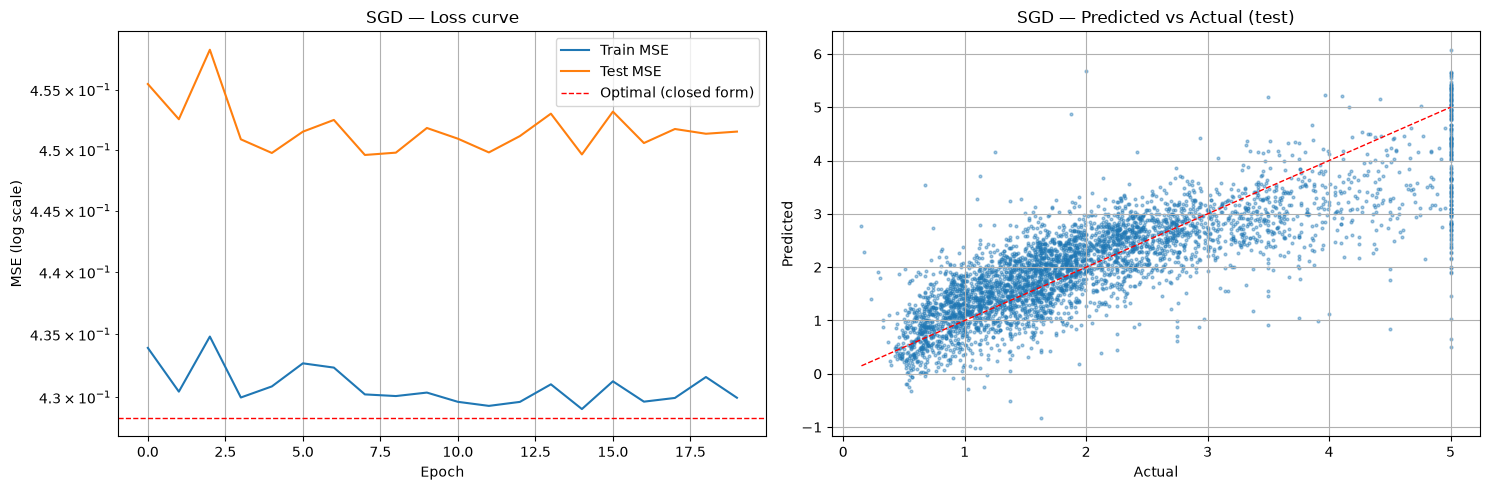

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history["train"], label="Train MSE")
axes[0].plot(history["test"], label="Test MSE")
axes[0].axhline(best_train_mse, color="red", ls="--", lw=1, label="Optimal (closed form)")
axes[0].set_yscale("log")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE (log scale)")
axes[0].set_title("SGD — Loss curve")
axes[0].legend()

y_pred = predict(X_test, w, b)
axes[1].scatter(y_test, y_pred, s=4, alpha=0.4)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, "r--", lw=1)
axes[1].set_xlabel("Actual"); axes[1].set_ylabel("Predicted")
axes[1].set_title("SGD — Predicted vs Actual (test)")
plt.tight_layout(); plt.show()

### الـ loss على مستوى الـ iterations (كل 500 خطوة)
هون بيبيّن التذبذب (noise) الخاص بالـ SGD:

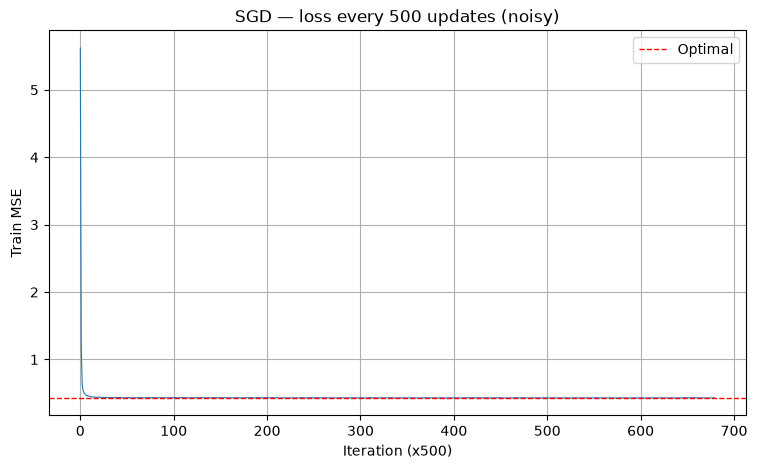

In [11]:
plt.plot(history["iter"], lw=0.8)
plt.axhline(best_train_mse, color="red", ls="--", lw=1, label="Optimal")
plt.xlabel("Iteration (x500)"); plt.ylabel("Train MSE")
plt.title("SGD — loss every 500 updates (noisy)")
plt.legend(); plt.show()

### مقارنة الأوزان مع الحل الأمثل

In [12]:
coef = pd.DataFrame({
    "Optimizer w": w,
    "Closed-form w": ref.coef_,
}, index=data.feature_names).round(4)
coef.loc["bias"] = [b, ref.intercept_]
coef

,Optimizer w,Closed-form w
MedInc,0.889700,0.874400
HouseAge,0.155200,0.155700
AveRooms,-0.165700,-0.189800
AveBedrms,0.177400,0.182600
Population,0.042700,0.049600
AveOccup,-0.264800,-0.258600
Latitude,-0.890700,-0.883700
Longitude,-0.812900,-0.818700
bias,2.084311,2.071947


## 7) تجربة: تأثير الـ Learning Rate

نفس الـ optimizer بس بقيم مختلفة للـ learning rate، حتى نشوف شو بيصير إذا كانت صغيرة كتير (بطء) أو كبيرة كتير (تذبذب / divergence).

lr = 0.0001   final train MSE = 0.43021


lr = 0.001    final train MSE = 0.43673


lr = 0.01     final train MSE = 0.47541


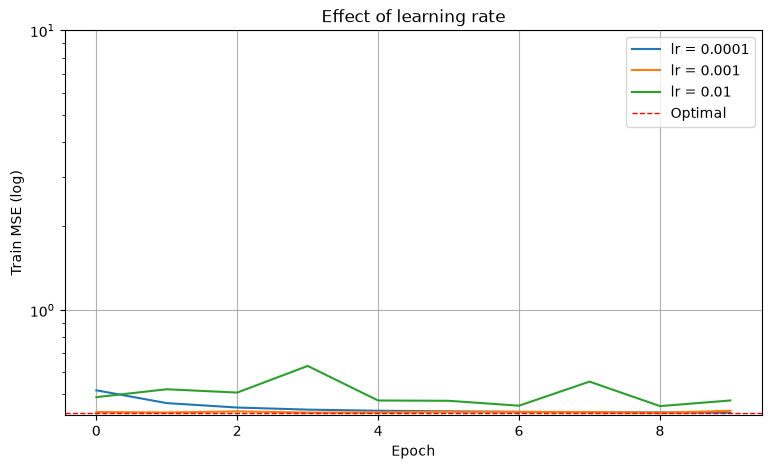

In [13]:
plt.figure(figsize=(9, 5))
for lr in [0.0001, 0.001, 0.01]:
    _, _, h = train(lr=lr, epochs=10)
    tr = np.array(h["train"])
    tr = np.where(np.isfinite(tr), tr, np.nan)
    plt.plot(tr, label=f"lr = {lr}")
    print(f"lr = {lr:<8} final train MSE = {h['train'][-1]:.5g}")
plt.axhline(best_train_mse, color="red", ls="--", lw=1, label="Optimal")
plt.yscale("log"); plt.ylim(top=10)
plt.xlabel("Epoch"); plt.ylabel("Train MSE (log)")
plt.title("Effect of learning rate")
plt.legend(); plt.show()

## 8) الخلاصة

- SGD بيعمل **~16,500 update بكل epoch** (update لكل عيّنة)، فبيوصل لـ loss قريب من الأمثل خلال epochs قليلة جداً.
- منحنى الـ loss على مستوى الـ iterations **متذبذب** بسبب إنو كل gradient محسوب من عيّنة وحدة (noisy).
- استخدمنا **learning-rate decay** حتى يخفّ التذبذب مع الوقت ويستقر قريب من الحل.
- learning rate كبيرة (0.01) بتعمل تذبذب واضح، وصغيرة كتير (0.0001) بتبطّئ التقارب.
- عيبه إنه ما بيستفيد من الـ vectorization، فوقت الـ epoch أطول بكتير من Batch GD.